In [1]:
import pandas as pd, numpy as np
from pathlib import Path

R = Path("../results")
NOMBRE = {"df": "DataFrame", "sql": "Spark SQL", "udf": "DataFrame + UDF", "rdd": "RDD"}
ORDEN = ["df", "sql", "udf", "rdd"]
QS = ["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"]

m = pd.read_csv(R / "mediciones_wsl.csv", dtype={"nucleos": str})
m = m[(m.ronda > 0) & (m.estado == "OK")]
print("Mediciones usadas:", len(m), "(deben ser 144)")

# Mediana, mínimo y máximo de las 3 rondas de cada combinación
res = (m.groupby(["consulta", "variante", "nucleos"]).segundos
         .agg(mediana="median", minimo="min", maximo="max").reset_index())

# Cuántas veces más rápida es cada variante que RDD
rdd = res[res.variante == "rdd"].set_index(["consulta", "nucleos"]).mediana
res["veces_mas_rapida_que_rdd"] = res.apply(lambda r: rdd[(r.consulta, r.nucleos)] / r.mediana, axis=1)

# Cuánto mejora cada combinación al pasar de 1 núcleo a todos
acel = res.pivot_table(index=["consulta", "variante"], columns="nucleos", values="mediana")
acel["aceleracion"] = acel["1"] / acel["*"]

res.to_csv(R / "resumen_tiempos.csv", index=False)
acel.round(3).to_csv(R / "aceleracion_nucleos.csv")

def tabla(datos, columna, titulo, decimales):
    t = datos.pivot(index="consulta", columns="variante", values=columna)[ORDEN].rename(columns=NOMBRE)
    print(f"\n{titulo}\n{t.round(decimales)}")

tabla(res[res.nucleos == "*"], "mediana", "Mediana del tiempo (s), todos los núcleos:", 2)
tabla(res[res.nucleos == "1"], "mediana", "Mediana del tiempo (s), un núcleo:", 2)
tabla(res[res.nucleos == "*"], "veces_mas_rapida_que_rdd", "Veces más rápida que RDD, todos los núcleos:", 1)
print("\nAceleración de 1 núcleo a todos (veces):")
print(acel["aceleracion"].unstack()[ORDEN].rename(columns=NOMBRE).round(1))

# Efecto de la primera ronda
rondas = m.pivot_table(index=["consulta", "variante", "nucleos"], columns="ronda", values="segundos")
rondas["r1_vs_r23"] = rondas[1] / rondas[[2, 3]].mean(axis=1)
print(f"\nCombinaciones en las que la ronda 1 fue más de 20 % más lenta que las rondas 2 y 3: "
      f"{(rondas.r1_vs_r23 > 1.2).sum()} de {len(rondas)}")

Mediciones usadas: 144 (deben ser 144)

Mediana del tiempo (s), todos los núcleos:
variante  DataFrame  Spark SQL  DataFrame + UDF   RDD
consulta                                             
Q1             0.33       0.28             1.30  2.50
Q2             0.31       0.31             0.54  3.62
Q3             0.62       0.58             1.52  3.50
Q4             1.92       2.06             2.79  6.79
Q5             0.68       0.68             2.00  4.87
Q6             1.04       1.32             2.26  3.76

Mediana del tiempo (s), un núcleo:
variante  DataFrame  Spark SQL  DataFrame + UDF    RDD
consulta                                              
Q1             0.72       0.71             3.11   6.65
Q2             0.81       0.82             0.71   8.06
Q3             1.73       1.68             3.35  12.92
Q4             4.33       4.44             5.40  15.96
Q5             1.28       1.39             3.44   9.22
Q6             5.71       6.17             7.79   9.33

Veces má

In [7]:
sin_r1 = (m[m.ronda > 1].groupby(["consulta", "variante", "nucleos"]).segundos.median()
          .rename("mediana_sin_r1"))
comp = res.set_index(["consulta", "variante", "nucleos"]).join(sin_r1)
comp["cambio_%"] = 100 * (comp.mediana_sin_r1 / comp.mediana - 1)
print("Cambio de la mediana al excluir la ronda 1:")
print(f"  promedio {comp['cambio_%'].mean():.1f} %, mínimo {comp['cambio_%'].min():.1f} %, máximo {comp['cambio_%'].max():.1f} %")
orden_igual = all(
    list(comp.xs((q, n), level=["consulta", "nucleos"]).mediana.sort_values().index) ==
    list(comp.xs((q, n), level=["consulta", "nucleos"]).mediana_sin_r1.sort_values().index)
    for q in QS for n in ["1", "*"])
print("¿El orden de las variantes (de más rápida a más lenta) se mantiene en todas las consultas?", orden_igual)

Cambio de la mediana al excluir la ronda 1:
  promedio -0.6 %, mínimo -12.1 %, máximo 38.5 %
¿El orden de las variantes (de más rápida a más lenta) se mantiene en todas las consultas? False


In [8]:
print("Combinaciones cuya mediana cambia más de 10 % al excluir la ronda 1:")
grandes = comp.loc[comp["cambio_%"].abs() > 10, ["mediana", "mediana_sin_r1", "cambio_%"]]
print(grandes.round(2).to_string())

print("\nConsultas donde cambia el orden de las variantes:")
for q in QS:
    for n in ["1", "*"]:
        c = comp.xs((q, n), level=["consulta", "nucleos"])
        antes = [NOMBRE[v] for v in c.mediana.sort_values().index]
        despues = [NOMBRE[v] for v in c.mediana_sin_r1.sort_values().index]
        if antes != despues:
            print(f"  {q}, núcleos={n}")
            print(f"     con ronda 1: {' < '.join(antes)}")
            print(f"     sin ronda 1: {' < '.join(despues)}")

print("\nConclusiones principales sin la ronda 1:")
rdd_ultima = all(comp.xs((q, n), level=["consulta", "nucleos"]).mediana_sin_r1.idxmax() == "rdd"
                 for q in QS for n in ["1", "*"])
print("  ¿RDD sigue siendo la más lenta en las 12 comparaciones?", rdd_ultima)
udf_media = all(
    (lambda c: c["udf"] > min(c["df"], c["sql"]) and c["udf"] < c["rdd"])
    (comp.xs((q, n), level=["consulta", "nucleos"]).mediana_sin_r1)
    for q in QS for n in ["1", "*"] if q != "Q2")
print("  ¿La UDF sigue entre DataFrame/SQL y RDD (sin contar la Q2)?", udf_media)

Combinaciones cuya mediana cambia más de 10 % al excluir la ronda 1:
                           mediana  mediana_sin_r1  cambio_%
consulta variante nucleos                                   
Q1       df       *           0.33            0.39     17.52
         sql      *           0.28            0.38     38.49
Q4       sql      *           2.06            1.81    -12.14

Consultas donde cambia el orden de las variantes:
  Q5, núcleos=*
     con ronda 1: DataFrame < Spark SQL < DataFrame + UDF < RDD
     sin ronda 1: Spark SQL < DataFrame < DataFrame + UDF < RDD

Conclusiones principales sin la ronda 1:
  ¿RDD sigue siendo la más lenta en las 12 comparaciones? True
  ¿La UDF sigue entre DataFrame/SQL y RDD (sin contar la Q2)? True


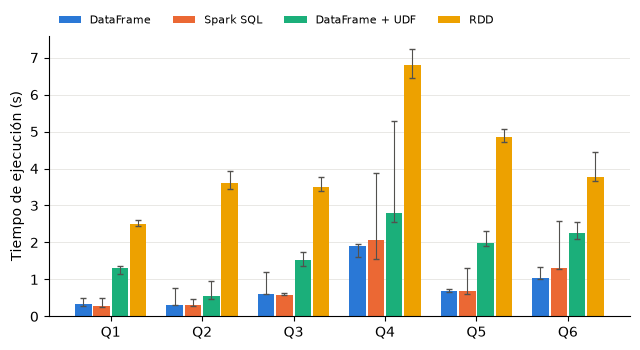

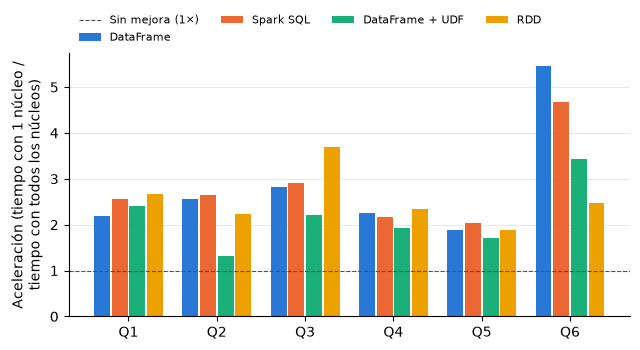

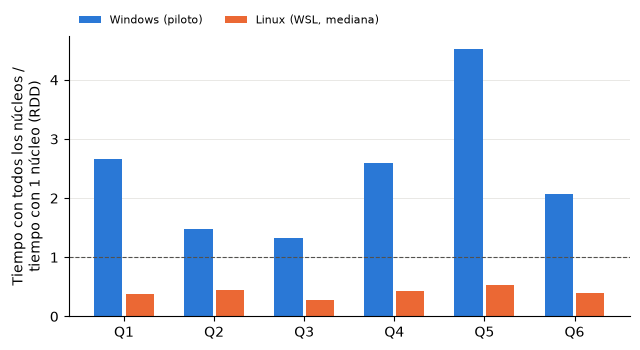

In [4]:
import matplotlib.pyplot as plt

COLOR = {"df": "#2a78d6", "sql": "#eb6834", "udf": "#1baf7a", "rdd": "#eda100"}
FIG = R / "figuras"
FIG.mkdir(exist_ok=True)
x, w = np.arange(len(QS)), 0.2

def estilo(ax, ylabel):
    ax.set_xticks(x, QS)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", color="#e5e4e0", lw=0.6)
    ax.set_axisbelow(True)
    for lado in ["top", "right"]:
        ax.spines[lado].set_visible(False)
    ax.legend(frameon=False, ncol=4, fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.0))

# Figura 1: tiempos con todos los núcleos (barra = mediana; línea = mínimo a máximo)
t = res[res.nucleos == "*"]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for i, v in enumerate(ORDEN):
    d = t[t.variante == v].set_index("consulta").loc[QS]
    ax.bar(x + (i - 1.5) * w, d.mediana, w * 0.9, color=COLOR[v], label=NOMBRE[v],
           yerr=[d.mediana - d.minimo, d.maximo - d.mediana],
           error_kw=dict(lw=0.8, capsize=2, ecolor="#52514e"))
estilo(ax, "Tiempo de ejecución (s)")
fig.tight_layout()
fig.savefig(FIG / "fig1_tiempos_todos_nucleos.png", dpi=300)

# Figura 2: aceleración de 1 núcleo a todos
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for i, v in enumerate(ORDEN):
    d = acel.xs(v, level="variante").loc[QS, "aceleracion"]
    ax.bar(x + (i - 1.5) * w, d, w * 0.9, color=COLOR[v], label=NOMBRE[v])
ax.axhline(1, color="#52514e", lw=0.8, ls="--", label="Sin mejora (1×)")
estilo(ax, "Aceleración (tiempo con 1 núcleo /\ntiempo con todos los núcleos)")
fig.tight_layout()
fig.savefig(FIG / "fig2_aceleracion_nucleos.png", dpi=300)

# Figura 3: Windows vs. Linux, variante RDD (tiempo con todos los núcleos / tiempo con 1)
w_ = pd.read_csv(R / "mediciones_windows.csv", dtype={"nucleos": str})
w_ = w_[(w_.variante == "rdd") & (w_.estado == "OK")].pivot_table(index="consulta", columns="nucleos", values="segundos")
lin = acel.xs("rdd", level="variante")
razon = pd.DataFrame({"Windows (piloto)": w_["*"] / w_["1"],
                      "Linux (WSL, mediana)": lin["*"] / lin["1"]}).loc[QS]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for i, (serie, color) in enumerate(zip(razon.columns, ["#2a78d6", "#eb6834"])):
    ax.bar(x + (i - 0.5) * 0.35, razon[serie], 0.35 * 0.9, color=color, label=serie)
ax.axhline(1, color="#52514e", lw=0.8, ls="--")
estilo(ax, "Tiempo con todos los núcleos /\ntiempo con 1 núcleo (RDD)")
ax.legend(frameon=False, ncol=2, fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.0))
fig.tight_layout()
fig.savefig(FIG / "fig3_windows_vs_linux_rdd.png", dpi=300)
plt.show()

In [3]:
import os, sys, re
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
from pyspark.sql import SparkSession
from consultas import CONSULTAS

spark = (SparkSession.builder.master("local[*]").appName("planes")
         .config("spark.driver.memory", "8g")
         .config("spark.sql.optimizer.excludedRules",
                 "org.apache.spark.sql.catalyst.optimizer.InferFiltersFromConstraints")
         .getOrCreate())
df = spark.read.parquet("../data/secop.parquet")
PLANES = R / "planes"
PLANES.mkdir(exist_ok=True)

def arbol_final(texto):
    # Con ejecución adaptativa, el plan trae una parte "Final" y otra "Initial"; nos quedamos con la final
    if "== Final Plan ==" in texto:
        return texto.split("== Final Plan ==")[1].split("== Initial Plan ==")[0]
    return texto.split("\n\n\n")[0]

def cuenta(arbol, nodo):
    return len(re.findall(rf"\b{nodo} \(\d+\)", arbol))

filas, arboles = [], {}
for q in QS:
    for v in ["df", "sql", "udf"]:
        r = CONSULTAS[q][v](df)
        r.collect()                         # ejecuta la consulta para que Spark fije el plan final
        texto = spark._jvm.PythonSQLUtils.explainString(r._jdf.queryExecution(), "formatted")
        (PLANES / f"{q}_{v}.txt").write_text(texto, encoding="utf-8")
        arbol = arbol_final(texto)
        arboles[(q, v)] = re.sub(r"#\d+|\(\d+\)", "", arbol)   # sin números internos, para comparar
        columnas = re.findall(r"ReadSchema: struct<(.*?)>", texto)
        filas.append({
            "consulta": q, "variante": NOMBRE[v],
            "llamadas_python": cuenta(arbol, "BatchEvalPython"),
            "intercambios_shuffle": cuenta(arbol, "Exchange"),
            "broadcast_join": cuenta(arbol, "BroadcastHashJoin"),
            "sort_merge_join": cuenta(arbol, "SortMergeJoin"),
            "ventanas": cuenta(arbol, "Window"),
            "ordenamientos": cuenta(arbol, "Sort"),
            "columnas_leidas": max((c.count(":") for c in columnas), default=0),
            "filtros_empujados": "; ".join(sorted(set(re.findall(r"PushedFilters: \[(.*?)\]", texto)))),
        })
    # RDD: no tiene plan optimizado; se guarda su linaje (la cadena de pasos que ejecuta)
    linaje = CONSULTAS[q]["rdd"](df).toDebugString().decode()
    (PLANES / f"{q}_rdd.txt").write_text(linaje, encoding="utf-8")
    filas.append({"consulta": q, "variante": "RDD",
                  "intercambios_shuffle": linaje.count("ShuffledRDD")})

ind = pd.DataFrame(filas)
ind.to_csv(R / "indicadores_planes.csv", index=False)
pd.set_option("display.width", 200, "display.max_colwidth", 60)
print(ind.fillna("").to_string(index=False))

print("\n¿El plan de DataFrame es idéntico al de Spark SQL?")
for q in QS:
    print(f"  {q}: {'sí' if arboles[(q, 'df')] == arboles[(q, 'sql')] else 'NO'}")
spark.stop()

26/10/28 07:47:16 WARN Utils: Your hostname, Ever resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/10/28 07:47:16 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/28 07:47:17 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
/tmp/ipykernel_14421/3970924285.py:55: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  print(ind.fillna("").to_string(index=False))


consulta        variante llamadas_python  intercambios_shuffle broadcast_join sort_merge_join ventanas ordenamientos columnas_leidas        filtros_empujados
      Q1       DataFrame             0.0                     1            0.0             0.0      0.0           0.0             2.0                         
      Q1       Spark SQL             0.0                     1            0.0             0.0      0.0           0.0             2.0                         
      Q1 DataFrame + UDF             1.0                     1            0.0             0.0      0.0           0.0             2.0                         
      Q1             RDD                                     1                                                                                               
      Q2       DataFrame             0.0                     0            0.0             0.0      0.0           0.0             5.0 GreaterThan(valor,1.0E8)
      Q2       Spark SQL             0.0            

In [5]:
import difflib

def plan(q, v):
    return (PLANES / f"{q}_{v}.txt").read_text(encoding="utf-8")

def contar(arbol, patron):
    return len(re.findall(patron, arbol))

print("Verificación de nodos en el plan final:")
for q, v in [("Q5", "df"), ("Q5", "sql"), ("Q5", "udf"), ("Q6", "df"), ("Q6", "sql")]:
    a = arbol_final(plan(q, v))
    print(f"  {q} {v:>3}: broadcast join={contar(a, r'BroadcastHashJoin')}, "
          f"sort-merge join={contar(a, r'SortMergeJoin')}, "
          f"shuffle reutilizado={contar(a, r'ReusedExchange')}, "
          f"límite por grupo={contar(a, r'WindowGroupLimit')}, "
          f"llamadas a Python={contar(a, r'BatchEvalPython')}")

print("\n=== Q2 con UDF: plan final (¿el filtro por valor va antes de la UDF?) ===")
print(arbol_final(plan("Q2", "udf")))

print("\n=== Q6: diferencias entre el plan de DataFrame (-) y el de SQL (+) ===")
limpio = lambda t: re.sub(r"#\d+|\(\d+\)", "", arbol_final(t)).strip().splitlines()
for linea in difflib.unified_diff(limpio(plan("Q6", "df")), limpio(plan("Q6", "sql")), lineterm="", n=1):
    print(linea)


Verificación de nodos en el plan final:
  Q5  df: broadcast join=1, sort-merge join=0, shuffle reutilizado=1, límite por grupo=0, llamadas a Python=0
  Q5 sql: broadcast join=1, sort-merge join=0, shuffle reutilizado=1, límite por grupo=0, llamadas a Python=0
  Q5 udf: broadcast join=1, sort-merge join=0, shuffle reutilizado=1, límite por grupo=0, llamadas a Python=1
  Q6  df: broadcast join=0, sort-merge join=0, shuffle reutilizado=0, límite por grupo=2, llamadas a Python=0
  Q6 sql: broadcast join=0, sort-merge join=0, shuffle reutilizado=0, límite por grupo=2, llamadas a Python=0

=== Q2 con UDF: plan final (¿el filtro por valor va antes de la UDF?) ===
== Physical Plan ==
* Project (6)
+- * Filter (5)
   +- BatchEvalPython (4)
      +- * Filter (3)
         +- * ColumnarToRow (2)
            +- Scan parquet  (1)

=== Q6: diferencias entre el plan de DataFrame (-) y el de SQL (+) ===
--- 
+++ 
@@ -6,3 +6,3 @@
                +- AQEShuffleRead 
-                  +- ShuffleQueryStage

In [6]:
def detalle(q, v, nodo):
    texto = plan(q, v)
    bloques = re.split(r"\n(?=\(\d+\) )", texto)
    return [b for b in bloques if re.match(rf"\(\d+\) {nodo}", b)]

print("=== Q2 con UDF: condición de cada filtro ===")
for b in detalle("Q2", "udf", "Filter"):
    print(b.strip(), "\n")

print("=== Q6: columnas que viajan en el shuffle ===")
for v in ["df", "sql"]:
    for b in detalle("Q6", v, "Exchange"):
        entrada = re.search(r"Input \[\d+\]: \[(.*?)\]", b)
        print(f"{v:>3}: {entrada.group(1) if entrada else b.strip()}")

=== Q2 con UDF: condición de cada filtro ===
(3) Filter [codegen id : 1]
Input [5]: [id_contrato#0, departamento#1, nombre_entidad#2, fecha#5, valor#7]
Condition : (valor#7 > 1.0E8) 

(5) Filter [codegen id : 2]
Input [6]: [id_contrato#0, departamento#1, nombre_entidad#2, fecha#5, valor#7, pythonUDF0#113]
Condition : (pythonUDF0#113 = ANTIOQUIA) 

=== Q6: columnas que viajan en el shuffle ===
 df: id_contrato#0, anio#6, valor#7, entidad#498
 df: id_contrato#0, anio#6, valor#7, entidad#498
sql: entidad#524, anio#6, id_contrato#0, valor#7, _w0#527
sql: entidad#524, anio#6, id_contrato#0, valor#7, _w0#527
